In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Đọc dữ liệu sạch
df = pd.read_csv("data/phongtro_clean.csv")
print(f"Tổng số mẫu: {df.shape[0]} dòng | Số cột: {df.shape[1]} cột")

Tổng số mẫu: 1288 dòng | Số cột: 24 cột


C:\Users\bobby\AppData\Local\Temp\ipykernel_15928\2210084014.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x="price", y="district", order=order_dist, ax=axes[2], palette="viridis")


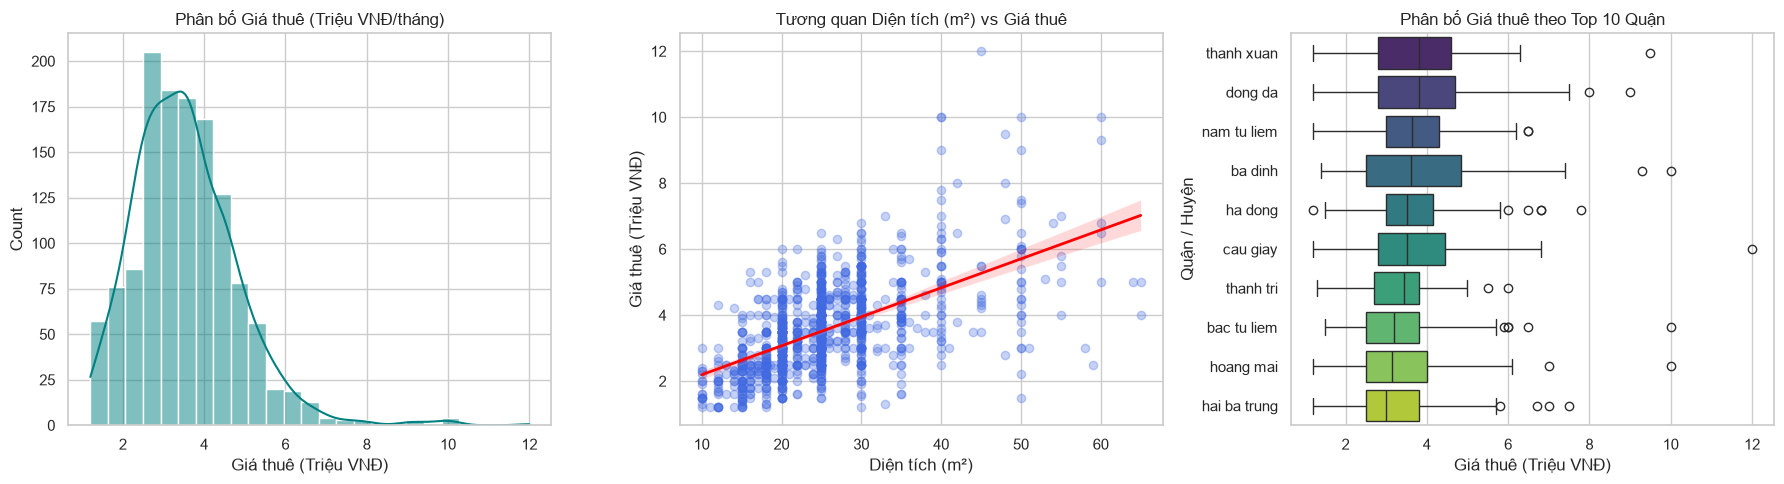

In [43]:
# Cấu hình hiển thị biểu đồ
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Phân bố giá thuê phòng
sns.histplot(df["price"], bins=25, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Phân bố Giá thuê (Triệu VNĐ/tháng)")
axes[0].set_xlabel("Giá thuê (Triệu VNĐ)")

# 2. Tương quan giữa Diện tích và Giá thuê
sns.regplot(
    data=df, x="area", y="price", ax=axes[1],
    scatter_kws={"alpha": 0.3, "color": "royalblue"},
    line_kws={"color": "red", "linewidth": 2}
)
axes[1].set_title("Tương quan Diện tích (m²) vs Giá thuê")
axes[1].set_xlabel("Diện tích (m²)")
axes[1].set_ylabel("Giá thuê (Triệu VNĐ)")

# 3. Giá thuê trung bình tại Top 10 Quận nhiều tin nhất
top10_dist = df["district"].value_counts().head(10).index
df_top10 = df[df["district"].isin(top10_dist)]
order_dist = df_top10.groupby("district")["price"].median().sort_values(ascending=False).index

sns.boxplot(data=df_top10, x="price", y="district", order=order_dist, ax=axes[2], palette="viridis")
axes[2].set_title("Phân bố Giá thuê theo Top 10 Quận")
axes[2].set_xlabel("Giá thuê (Triệu VNĐ)")
axes[2].set_ylabel("Quận / Huyện")

plt.tight_layout()
plt.show()

In [44]:
# 1. Chỉ giữ các quận có từ 15 mẫu trở lên để đảm bảo đủ dữ liệu cho cả Train và Test, các quận khác gộp lại với nhau
dist_counts = df["district"].value_counts()
valid_districts = dist_counts[dist_counts >= 15].index

df_model = df.copy()
df_model["district"] = df_model["district"].where(df_model["district"].isin(valid_districts), other="khac")

print(f"Có {len(valid_districts)} quận với hơn 15 mẫu và còn lại {len(dist_counts) - len(valid_districts)} quận là nhóm lại")

# 2. Danh sách các cột đặc trưng (Features)
binary_cols = [
    "has_ac", "has_loft", "has_balcony", "private_wc", "free_hours",
    "no_shared_owner", "has_elevator", "has_washer", "has_fridge",
    "furnished", "has_security", "has_parking"
]
feature_cols = ["area", "district", "ptype"] + binary_cols

df_model = df_model[feature_cols + ["price"]].dropna()
stratify_col = df_model["district"]  # Lưu lại để chia đều tỷ lệ Quận giữa Train và Test

# 3. One-Hot Encoding cho biến phân loại (district và ptype)
# Bắt buộc dùng drop_first=True để tránh bẫy đa cộng tuyến (Dummy Variable Trap)
df_encoded = pd.get_dummies(
    df_model, columns=["district", "ptype"], drop_first=True, dtype=int
)

X = df_encoded.drop(columns=["price"])
y = df_encoded["price"]

# 4. Chia tập Train (80%) và Test (20%) có phân tầng theo Quận
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify_col
)

print(f"Kích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Test : {X_test.shape}")

Có 13 quận với hơn 15 mẫu và còn lại 9 quận là nhóm lại
Kích thước tập Train: (1030, 29)
Kích thước tập Test : (258, 29)


In [45]:
liner_model = LinearRegression()
liner_model.fit(X_train, y_train)

y_train_predict = liner_model.predict(X_train)
y_test_predict = liner_model.predict(X_test)

def check_number(y_true, y_predict, name):
    mae = mean_absolute_error(y_true, y_predict)
    rmse = np.sqrt(mean_squared_error(y_true, y_predict))
    r2 = r2_score(y_true, y_predict)

    print(f"Tập {name}:")
    print(f"MAE     : {mae:.3f}")
    print(f"RMSE    : {rmse:.3f}")
    print(f"R^2     : {r2:.3f}")

check_number(y_train, y_train_predict, "Train")
check_number(y_test, y_test_predict, "Test")

Tập Train:
MAE     : 0.687
RMSE    : 0.934
R^2     : 0.481
Tập Test:
MAE     : 0.686
RMSE    : 0.929
R^2     : 0.457


In [46]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Ridge phạt theo độ lớn hệ số nên PHẢI chuẩn hóa đặc trưng trước
ridge_pipe = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-2, 3, 50), cv=5)   # tự chọn alpha bằng cross-validation
)
ridge_pipe.fit(X_train, y_train)

ridge  = ridge_pipe.named_steps["ridgecv"]
scaler = ridge_pipe.named_steps["standardscaler"]
print(f"Alpha được chọn: {ridge.alpha_:.3f}\n")

check_number(y_train, ridge_pipe.predict(X_train), "RIDGE - TRAIN")
check_number(y_test,  ridge_pipe.predict(X_test),  "RIDGE - TEST")

# Quy đổi hệ số về đơn vị gốc (triệu VNĐ / 1 đơn vị) để so với Linear Regression
coef_orig      = ridge.coef_ / scaler.scale_
intercept_orig = ridge.intercept_ - np.sum(ridge.coef_ * scaler.mean_ / scaler.scale_)

ols = LinearRegression().fit(X_train, y_train)
coef_cmp = pd.DataFrame({"OLS": ols.coef_, "Ridge": coef_orig}, index=X.columns)
display(coef_cmp.sort_values("Ridge", ascending=False).round(3))

Alpha được chọn: 59.636

Tập RIDGE - TRAIN:
MAE     : 0.688
RMSE    : 0.936
R^2     : 0.479
Tập RIDGE - TEST:
MAE     : 0.685
RMSE    : 0.933
R^2     : 0.452


,OLS,Ridge
has_elevator,0.487,0.475
furnished,0.356,0.347
has_fridge,0.269,0.270
district_tay ho,0.101,0.249
has_balcony,0.233,0.235
has_washer,0.172,0.173
has_security,0.151,0.133
district_dong da,-0.015,0.130
area,0.079,0.074
district_thanh xuan,-0.087,0.066


Tập RANDOM FOREST - TRAIN:
MAE     : 0.601
RMSE    : 0.822
R^2     : 0.598
Tập RANDOM FOREST - TEST:
MAE     : 0.725
RMSE    : 0.999
R^2     : 0.372
Tham số tốt nhất: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 3}
Tập RANDOM FOREST (đã tinh chỉnh) - TEST:
MAE     : 0.712
RMSE    : 0.982
R^2     : 0.393


,importance,std
area,0.498,0.053
furnished,0.030,0.013
has_elevator,0.023,0.010
district_dong da,0.016,0.004
private_wc,0.014,0.010
district_hoai duc,0.014,0.004
district_bac tu liem,0.013,0.003
district_thanh xuan,0.007,0.006
has_parking,0.006,0.005
has_ac,0.005,0.003


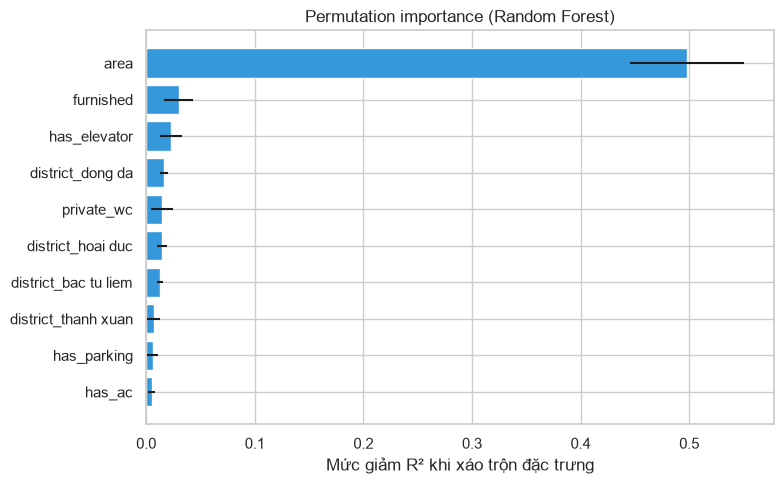

In [47]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

# Mô hình mặc định hợp lý
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
check_number(y_train, rf.predict(X_train), "RANDOM FOREST - TRAIN")
check_number(y_test,  rf.predict(X_test),  "RANDOM FOREST - TEST")

# Tinh chỉnh siêu tham số (chỉ dùng tập train)
grid = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    param_grid={
        "min_samples_leaf": [3, 5, 10, 20],
        "max_features": [0.33, 0.5, 1.0],
        "max_depth": [None, 8],
    },
    cv=5, scoring="neg_mean_absolute_error",
)
grid.fit(X_train, y_train)
print("Tham số tốt nhất:", grid.best_params_)
best_rf = grid.best_estimator_
check_number(y_test, best_rf.predict(X_test), "RANDOM FOREST (đã tinh chỉnh) - TEST")

# Độ quan trọng đặc trưng: dùng permutation importance trên tập TEST
pi = permutation_importance(best_rf, X_test, y_test, n_repeats=20, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std},
                   index=X.columns).sort_values("importance", ascending=False)
display(imp.head(10).round(3))

top = imp.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["importance"], xerr=top["std"], color="#3498db")
plt.xlabel("Mức giảm R² khi xáo trộn đặc trưng"); plt.title("Permutation importance (Random Forest)")
plt.tight_layout(); plt.show()

In [48]:
from sklearn.model_selection import RepeatedKFold, cross_validate

cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
rows = []
for name, mdl in {"Linear Regression": LinearRegression(),
                  "Ridge": ridge_pipe,
                  "Random Forest": best_rf}.items():
    r = cross_validate(mdl, X, y, cv=cv, scoring=("r2", "neg_mean_absolute_error"))
    rows.append({"Mô hình": name, "R² (CV)": r["test_r2"].mean(), "± R²": r["test_r2"].std(),   
                 "MAE (CV)": -r["test_neg_mean_absolute_error"].mean()})
display(pd.DataFrame(rows).set_index("Mô hình").round(3))

,R² (CV),± R²,MAE (CV)
Mô hình,,,
Linear Regression,0.441,0.035,0.705
Ridge,0.443,0.030,0.705
Random Forest,0.430,0.025,0.707


Sau khỉ thử nghiệm các mô hình khác nhau như **Liner Regression, Ridge và Random Forest**

Ta thấy các model cũng không khác nhau quá nhiều, do đó chúng ta chọn Liner Regression

In [49]:
model = liner_model

In [50]:
weights_df = pd.DataFrame({
    "Feature": X.columns,
    "Weight_Million_VND": model.coef_
})

is_district = weights_df["Feature"].str.startswith("district_")
is_ptype    = weights_df["Feature"].str.startswith("ptype_")

sort_desc = lambda d: d.sort_values("Weight_Million_VND", ascending=False)

district_w = sort_desc(weights_df[is_district])
ptype_w    = sort_desc(weights_df[is_ptype])
other_w    = sort_desc(weights_df[~(is_district | is_ptype)])

print(f"Intercept: {model.intercept_:.3f} triệu VNĐ\n")
for title, g in [("DISTRICT", district_w), ("PTYPE", ptype_w), ("AREA & AMENITIES", other_w)]:
    print(f"--- {title} ---")
    display(g.round(3))

Intercept: 1.770 triệu VNĐ

--- DISTRICT ---


,Feature,Weight_Million_VND
23,district_tay ho,0.101
15,district_dong da,-0.015
25,district_thanh xuan,-0.087
17,district_hai ba trung,-0.195
14,district_cau giay,-0.197
22,district_nam tu liem,-0.257
16,district_ha dong,-0.334
24,district_thanh tri,-0.432
19,district_hoang mai,-0.499
13,district_bac tu liem,-0.536


--- PTYPE ---


,Feature,Weight_Million_VND
26,ptype_can_ho_dich_vu,0.017
27,ptype_can_ho_mini,0.008
28,ptype_phong_tro,-0.112


--- AREA & AMENITIES ---


,Feature,Weight_Million_VND
7,has_elevator,0.487
10,furnished,0.356
9,has_fridge,0.269
3,has_balcony,0.233
8,has_washer,0.172
11,has_security,0.151
0,area,0.079
2,has_loft,-0.058
6,no_shared_owner,-0.089
5,free_hours,-0.123


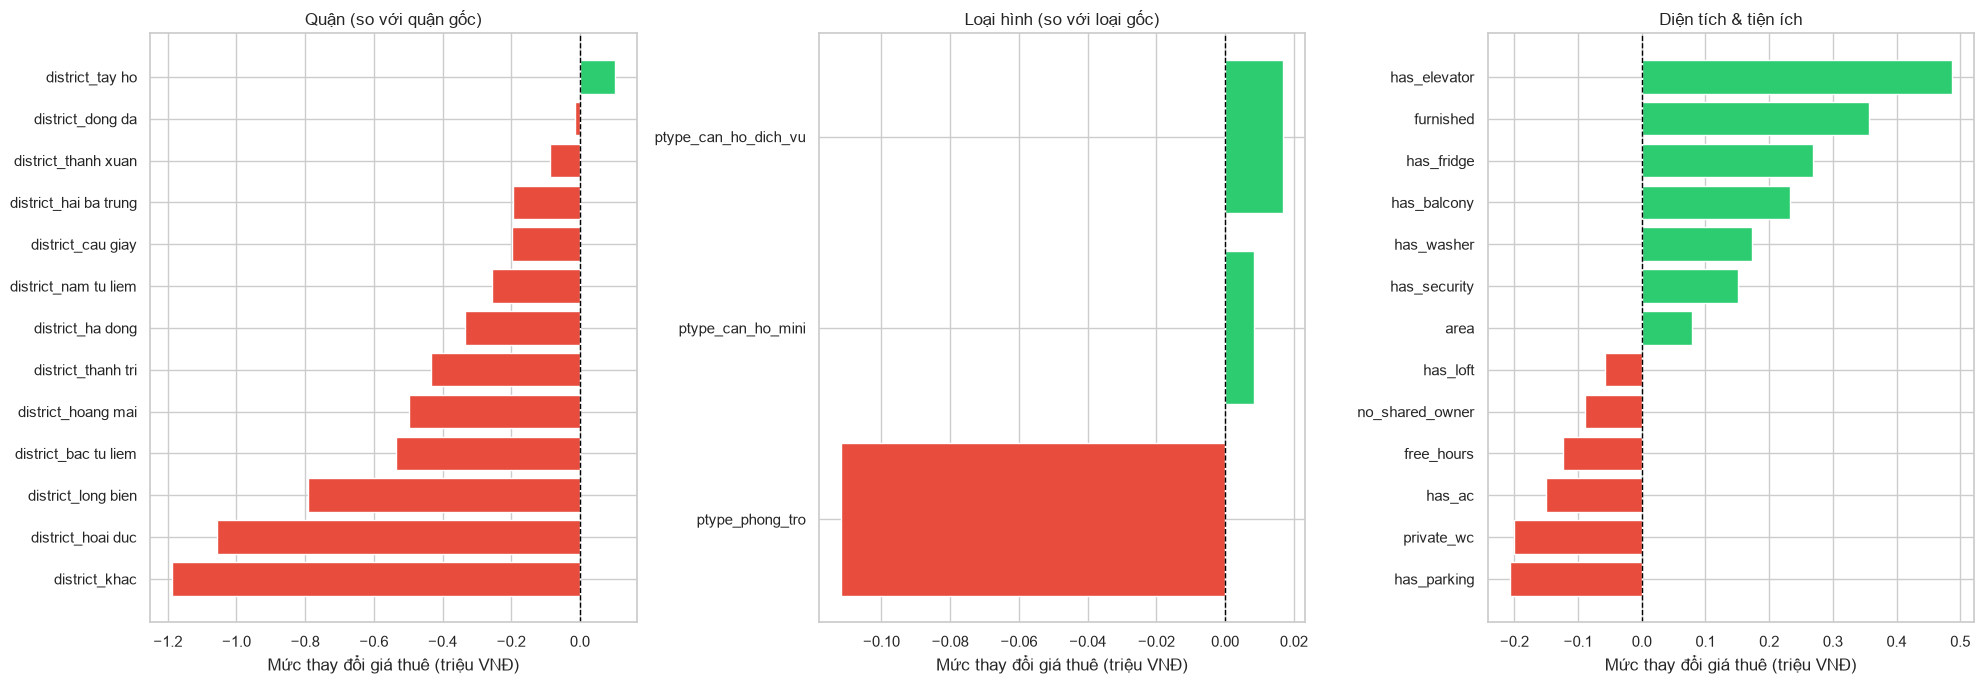

In [51]:
groups = {
    "Quận (so với quận gốc)": district_w,
    "Loại hình (so với loại gốc)": ptype_w,
    "Diện tích & tiện ích": other_w,
}
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (title, g) in zip(axes, groups.items()):
    colors = ["#2ecc71" if v >= 0 else "#e74c3c" for v in g["Weight_Million_VND"]]
    ax.barh(g["Feature"], g["Weight_Million_VND"], color=colors)
    ax.invert_yaxis()                      # hệ số lớn nhất nằm trên cùng
    ax.axvline(0, color="black", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("Mức thay đổi giá thuê (triệu VNĐ)")
plt.tight_layout()
plt.show()

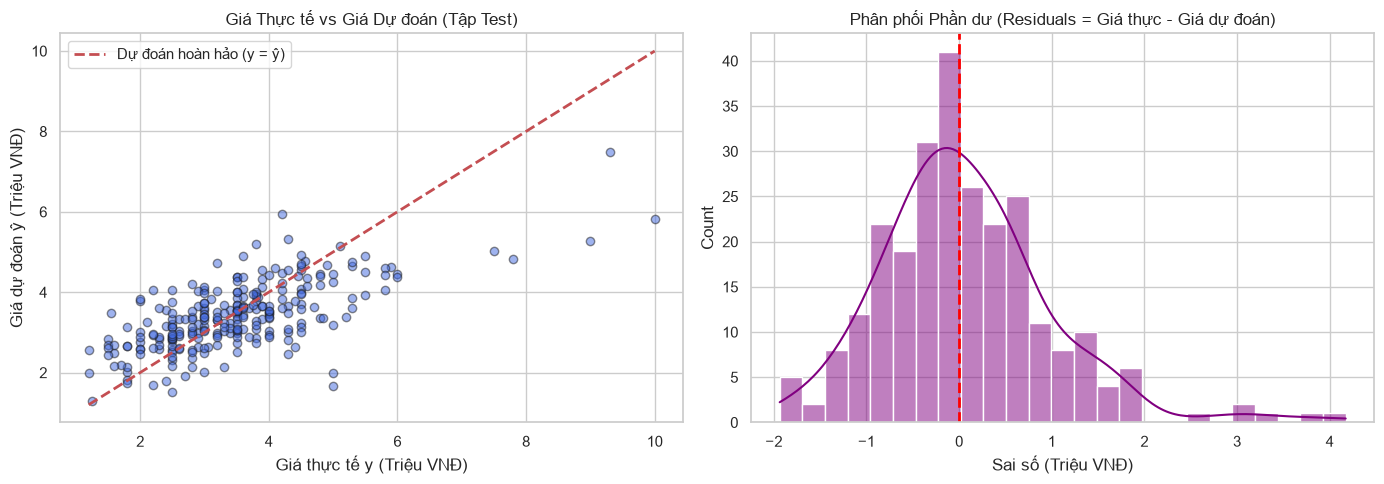

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scatter plot: Giá thực tế vs Giá dự đoán
axes[0].scatter(y_test, y_test_predict, alpha=0.5, color="royalblue", edgecolors="k")
min_val = min(y_test.min(), y_test_predict.min())
max_val = max(y_test.max(), y_test_predict.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Dự đoán hoàn hảo (y = ŷ)")
axes[0].set_title("Giá Thực tế vs Giá Dự đoán (Tập Test)")
axes[0].set_xlabel("Giá thực tế y (Triệu VNĐ)")
axes[0].set_ylabel("Giá dự đoán ŷ (Triệu VNĐ)")
axes[0].legend()

# 2. Phân bố sai số (Residuals = y_test - y_test_predict)
residuals = y_test - y_test_predict
sns.histplot(residuals, bins=25, kde=True, ax=axes[1], color="purple")
axes[1].axvline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Phân phối Phần dư (Residuals = Giá thực - Giá dự đoán)")
axes[1].set_xlabel("Sai số (Triệu VNĐ)")

plt.tight_layout()
plt.show()

In [55]:
import re, unicodedata

def norm_text(s):
    s = unicodedata.normalize("NFD", str(s).lower())
    s = "".join(c for c in s if unicodedata.category(c) != "Mn").replace("đ", "d")
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"^(quan|huyen|thi xa)\s+", "", s)

ALL_DISTRICTS = set(dist_counts.index)          # mọi quận trong dữ liệu gốc
VALID = set(valid_districts)                    # quận đủ >= 15 tin
PTYPES = {"phong_tro", "can_ho", "can_ho_mini", "can_ho_dich_vu"}
RMSE = float(np.sqrt(((y - model.predict(X)) ** 2).mean()))   # sai số điển hình

def dinh_gia_phong(area, district, ptype="phong_tro", asking_price=None, **amenities):
    d = norm_text(district)
    if d not in ALL_DISTRICTS:
        raise ValueError(f"Quận '{district}' không có trong dữ liệu: {sorted(ALL_DISTRICTS)}")
    if ptype not in PTYPES:
        raise ValueError(f"ptype phải thuộc {sorted(PTYPES)}")
    bad = set(amenities) - set(binary_cols)
    if bad:
        raise ValueError(f"Tiện ích không hợp lệ: {bad}")
    if not 10 <= area <= 65:
        print(f"! {area} m² ngoài khoảng dữ liệu (10-65 m²), kém tin cậy.")

    g = d if d in VALID else "khac"
    if g == "khac":
        print(f"! '{district}' ít dữ liệu, tính vào nhóm 'khac' (kém tin cậy).")

    row = pd.DataFrame(0.0, index=[0], columns=X.columns)
    row["area"] = area
    for k, v in amenities.items():
        row[k] = v
    for col in (f"district_{g}", f"ptype_{ptype}"):
        if col in row.columns:
            row[col] = 1

    pred = model.predict(row)[0]
    print(f"Giá ước tính: {pred:.2f} triệu/tháng (sai số điển hình ±{RMSE:.2f})")
    if asking_price is not None:
        diff = asking_price - pred
        print("=> " + ("THẤP hơn" if diff < -RMSE else "CAO hơn" if diff > RMSE
                       else "TRONG khoảng bình thường") + " so với mô hình")
    return pred

dinh_gia_phong(25, "Cầu Giấy", ptype="can_ho_mini", asking_price=4.2,
               has_ac=1, furnished=1, has_elevator=1, has_balcony=1)

Giá ước tính: 4.48 triệu/tháng (sai số điển hình ±0.93)
=> TRONG khoảng bình thường so với mô hình


np.float64(4.475382467084692)